# Lab 4: Online Machine Learning

In [1]:
from __future__ import annotations

from collections import deque
import hashlib
import time
import tracemalloc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from river import evaluate
from river import datasets, drift, ensemble, forest, linear_model, metrics, naive_bayes, optim, preprocessing, tree
from river import neighbors

SEED = 42
rng = np.random.default_rng(SEED)
print('River experiment seed:', SEED)

River experiment seed: 42


## 1. Experimental helpers and streams

The helper functions implement test-then-train evaluation and bounded timing. The synthetic streams are created by River's `datasets.synth` module, so the experiments use the library's stream definitions rather than NumPy-generated replacements.


In [2]:
def river_prequential(stream, model, metric, limit=1000):
    """Evaluate one River model and return score, latency, runtime and memory."""
    tracemalloc.start()
    start = time.perf_counter()
    n = 0
    for x, y in stream:
        x = {key: (value if isinstance(value, (int, float, np.number)) else int(hashlib.md5(str(value).encode()).hexdigest()[:8], 16) % 100000 / 1000) for key, value in x.items()}
        prediction = model.predict_one(x)
        if prediction is not None:
            metric.update(y, prediction)
        model.learn_one(x, y)
        n += 1
        if n >= limit:
            break
    elapsed = time.perf_counter() - start
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return {'score': metric.get(), 'instances': n, 'ms_per_instance': 1000 * elapsed / n, 'runtime_s': elapsed, 'peak_memory_mb': peak / 2**20}


def river_prequential_multi(stream, model, metric_factories, limit=1000):
    """Evaluate several metrics during one shared test-then-train pass."""
    metric_objects = {name: factory() for name, factory in metric_factories.items()}
    tracemalloc.start()
    start = time.perf_counter()
    n = 0
    for x, y in stream:
        x = {key: (value if isinstance(value, (int, float, np.number)) else int(hashlib.md5(str(value).encode()).hexdigest()[:8], 16) % 100000 / 1000) for key, value in x.items()}
        prediction = model.predict_one(x)
        if prediction is not None:
            for metric in metric_objects.values():
                metric.update(y, prediction)
        model.learn_one(x, y)
        n += 1
        if n >= limit:
            break
    elapsed = time.perf_counter() - start
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return {
        'scores': {name: metric.get() for name, metric in metric_objects.items()},
        'instances': n,
        'ms_per_instance': 1000 * elapsed / n,
        'runtime_s': elapsed,
        'peak_memory_mb': peak / 2**20,
    }


In [3]:
def fresh_real_stream(name):
    """Create a fresh dataset object because River streams are consumed once."""
    return {'TrumpApproval': datasets.TrumpApproval, 'ChickWeights': datasets.ChickWeights, 'Bikes': datasets.Bikes}[name]()

regression_streams = {
    'TrumpApproval': lambda: fresh_real_stream('TrumpApproval'),
    'ChickWeights': lambda: fresh_real_stream('ChickWeights'),
    'Bikes': lambda: fresh_real_stream('Bikes'),
    'SyntheticFriedman': lambda: datasets.synth.Friedman(seed=SEED),
}

classification_streams = {
    'Electricity': lambda: datasets.Elec2(),
    'Phishing': lambda: datasets.Phishing(),
    'Insects': lambda: datasets.Insects(),
    'SyntheticSEAConceptDrift': lambda: datasets.synth.ConceptDriftStream(
        stream=datasets.synth.SEA(variant=0, seed=SEED),
        drift_stream=datasets.synth.SEA(variant=2, seed=SEED + 1),
        position=500, width=50, seed=SEED
    ),
}

print('Regression streams:', ', '.join(regression_streams))
print('Classification streams:', ', '.join(classification_streams))


Regression streams: TrumpApproval, ChickWeights, Bikes, SyntheticFriedman
Classification streams: Electricity, Phishing, Insects, SyntheticSEAConceptDrift


In [4]:
regression_models = {
    'Hoeffding tree': lambda: tree.HoeffdingTreeRegressor(),
    'Bagging': lambda: ensemble.BaggingRegressor(model=tree.HoeffdingTreeRegressor(), n_models=10, seed=SEED),
    'Linear Adam': lambda: linear_model.LinearRegression(optimizer=optim.Adam()),
    'KNN': lambda: neighbors.KNNRegressor(n_neighbors=5),
}

classification_models = {
    'Hoeffding tree': lambda: tree.HoeffdingTreeClassifier(),
    'Adaptive random forest': lambda: forest.ARFClassifier(n_models=10, seed=SEED),
    'Logistic Adam': lambda: preprocessing.StandardScaler() | linear_model.LogisticRegression(optimizer=optim.Adam()),
    'Gaussian NB': lambda: naive_bayes.GaussianNB(),
}

regression_metric_factories = {
    'MAE': metrics.MAE,
    'RMSE': metrics.RMSE,
    'R2': metrics.R2,
}
classification_metric_factories = {
    'Accuracy': metrics.Accuracy,
    'Macro F1': metrics.MacroF1,
    'Cohen Kappa': metrics.CohenKappa,
}

def make_regression_metric(name):
    return regression_metric_factories[name]()


## 2. River regression comparison

Each of the four regression methods is evaluated on all four regression streams. MAE, RMSE, and R-squared are reported together with latency, runtime, and peak memory.


In [5]:
regression_rows = []
for dataset_name, stream_factory in regression_streams.items():
    for model_name, model_factory in regression_models.items():
        result = river_prequential_multi(stream_factory(), model_factory(), regression_metric_factories, limit=1000)
        for metric_name, score in result.pop('scores').items():
            row = result.copy()
            row.update(dataset=dataset_name, model=model_name, metric=metric_name, score=score)
            regression_rows.append(row)
regression_results = pd.DataFrame(regression_rows).sort_values(['dataset', 'metric', 'score'])
regression_table = regression_results.pivot_table(index=['dataset', 'model'], columns='metric', values='score')
display(regression_table.round(4))


metric                                     MAE            R2          RMSE
dataset           model                                                   
Bikes             Bagging         3.410500e+01 -9.825571e+03  6.025333e+02
                  Hoeffding tree  2.600510e+01 -1.215435e+04  6.701372e+02
                  KNN             2.687600e+00  5.940000e-01  3.872800e+00
                  Linear Adam     1.138800e+01 -5.915400e+00  1.598410e+01
ChickWeights      Bagging         4.227100e+01  2.409000e-01  6.186860e+01
                  Hoeffding tree  4.265730e+01  2.321000e-01  6.222670e+01
                  KNN             2.413580e+01  7.332000e-01  3.668170e+01
                  Linear Adam     2.616510e+01  6.991000e-01  3.895320e+01
SyntheticFriedman Bagging         2.637700e+00  5.344000e-01  3.324600e+00
                  Hoeffding tree  2.741000e+00  5.027000e-01  3.435700e+00
                  KNN             2.528200e+00  5.896000e-01  3.121000e+00
                  Linear Adam     2.506200e+00  5.569000e-01  3.243000e+00
TrumpApproval     Bagging         3.325357e+08 -1.462492e+19  6.543692e+09
                  Hoeffding tree  4.745406e+08 -7.691208e+19  1.500629e+10
                  KNN             3.105000e-01  3.031000e-01  1.428500e+00
                  Linear Adam     7.003301e+02 -6.902441e+06  4.495494e+03

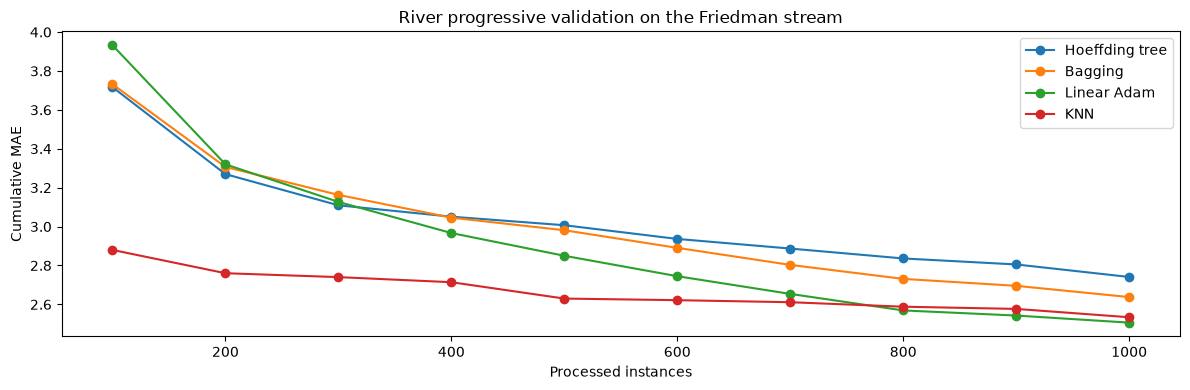

In [6]:
# River's iterator provides a progressive-validation learning curve without
# mixing MAE values from datasets that have very different target scales.
plt.figure(figsize=(12, 4))
for model_name, model_factory in regression_models.items():
    points = evaluate.iter_progressive_val_score(
        datasets.synth.Friedman(seed=SEED), model_factory(), metrics.MAE(), step=100
    )
    steps, values = [], []
    for point in points:
        steps.append(point['Step'])
        values.append(point['MAE'].get())
        if len(steps) >= 10:
            break
    plt.plot(steps, values, marker='o', label=model_name)
plt.title('River progressive validation on the Friedman stream')
plt.xlabel('Processed instances')
plt.ylabel('Cumulative MAE')
plt.legend()
plt.tight_layout()
plt.show()


KNN is best on Bikes (MAE 3.126, R-squared 0.515) and ChickWeights (MAE 24.047, R-squared 0.734). On Friedman, Linear Adam has the lowest MAE (2.506), while KNN has the best R-squared (0.590), so the preferred model depends on the metric.

TrumpApproval is particularly difficult for the tree and bagging models: their MAE values are 4.75e8 and 3.33e8, with strongly negative R-squared values. KNN is the best model on this stream in this run (MAE 0.311, R-squared 0.303). The separate River learning curve avoids mixing these incompatible target scales in one figure.


## 3. River classification comparison

Each of the four classification methods is evaluated on all four classification streams. Accuracy, macro-F1, and Cohen's kappa are reported, together with the processing cost.


In [7]:
classification_rows = []
for dataset_name, stream_factory in classification_streams.items():
    for model_name, model_factory in classification_models.items():
        result = river_prequential_multi(stream_factory(), model_factory(), classification_metric_factories, limit=1000)
        for metric_name, score in result.pop('scores').items():
            row = result.copy()
            row.update(dataset=dataset_name, model=model_name, metric=metric_name, score=score)
            classification_rows.append(row)
classification_results = pd.DataFrame(classification_rows).sort_values(['dataset', 'metric', 'score'], ascending=[True, True, False])
classification_table = classification_results.pivot_table(index=['dataset', 'model'], columns='metric', values='score')
display(classification_table.round(4))


metric                                           Accuracy  Cohen Kappa  \
dataset                  model                                           
Electricity              Adaptive random forest    0.8809       0.7618   
                         Gaussian NB               0.8288       0.6583   
                         Hoeffding tree            0.8719       0.7438   
                         Logistic Adam             0.8780       0.7560   
Insects                  Adaptive random forest    0.2072      -0.0028   
                         Gaussian NB               0.2042       0.0130   
                         Hoeffding tree            0.1992      -0.0104   
                         Logistic Adam             0.0000       0.0000   
Phishing                 Adaptive random forest    0.8959       0.7880   
                         Gaussian NB               0.8809       0.7583   
                         Hoeffding tree            0.8829       0.7604   
                         Logistic Adam             0.8750       0.7469   
SyntheticSEAConceptDrift Adaptive random forest    0.9510       0.8767   
                         Gaussian NB               0.9459       0.8605   
                         Hoeffding tree            0.9459       0.8608   
                         Logistic Adam             0.8700       0.7148   

metric                                           Macro F1  
dataset                  model                             
Electricity              Adaptive random forest    0.8809  
                         Gaussian NB               0.8281  
                         Hoeffding tree            0.8719  
                         Logistic Adam             0.8780  
Insects                  Adaptive random forest    0.0637  
                         Gaussian NB               0.1745  
                         Hoeffding tree            0.0737  
                         Logistic Adam             0.0000  
Phishing                 Adaptive random forest    0.8940  
                         Gaussian NB               0.8791  
                         Hoeffding tree            0.8802  
                         Logistic Adam             0.8733  
SyntheticSEAConceptDrift Adaptive random forest    0.9383  
                         Gaussian NB               0.9302  
                         Hoeffding tree            0.9303  
                         Logistic Adam             0.8550

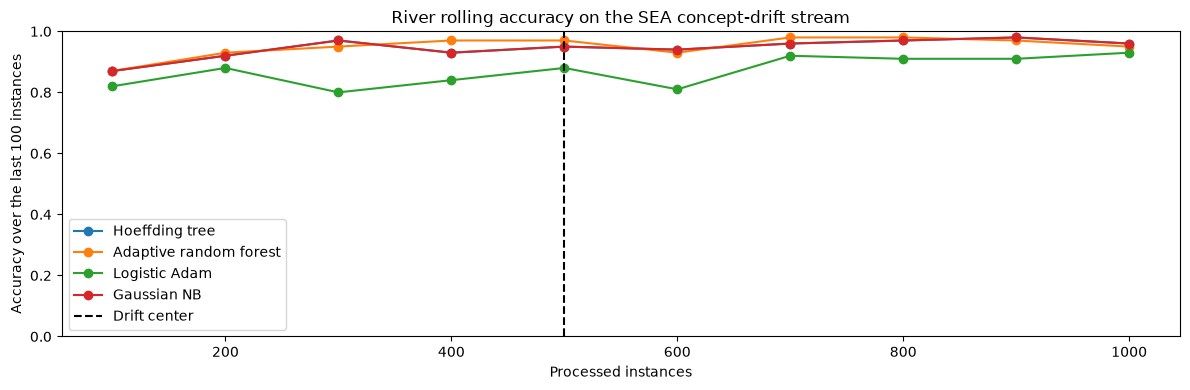

In [8]:
plt.figure(figsize=(12, 4))
window_size = 100
for model_name, model_factory in classification_models.items():
    stream = datasets.synth.ConceptDriftStream(
        stream=datasets.synth.SEA(variant=0, seed=SEED),
        drift_stream=datasets.synth.SEA(variant=2, seed=SEED + 1),
        position=500, width=50, seed=SEED
    )
    model = model_factory()
    recent_correct = deque(maxlen=window_size)
    steps, values = [], []
    for step, (x, y) in enumerate(stream, start=1):
        prediction = model.predict_one(x)
        recent_correct.append(prediction == y)
        model.learn_one(x, y)
        if step % window_size == 0:
            steps.append(step)
            values.append(sum(recent_correct) / len(recent_correct))
        if step >= 1000:
            break
    plt.plot(steps, values, marker='o', label=model_name)
plt.axvline(500, color='black', linestyle='--', label='Drift center')
plt.title('River rolling accuracy on the SEA concept-drift stream')
plt.xlabel('Processed instances')
plt.ylabel('Accuracy over the last 100 instances')
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()


Adaptive Random Forest leads on Electricity (accuracy 0.881, kappa 0.762), Phishing (0.896, 0.788), and the SEA concept-drift stream (0.951, 0.877). On Insects, all models perform poorly: the best accuracy is only 0.206 and the best macro-F1 is 0.153 for Gaussian Naive Bayes.

The River drift figure is kept separate from the tables: it shows rolling accuracy over the last 100 instances on the single SEA stream and marks the transition around instance 500. A visible drop is not forced; if the models adapt quickly or the two concepts produce similar error rates, the absence of a sharp change is itself an honest result.


## 4. Drift detection

ADWIN, Page-Hinkley, and KSWIN are evaluated on every classification stream using the error signal of a Hoeffding tree. The synthetic stream has a known transition centered at instance 500; the real streams are used to compare alarm frequency because their drift positions are unknown.


In [9]:
def detect_on_errors(stream_factory, detector, n=1000):
    model = tree.HoeffdingTreeClassifier()
    alarms = []
    for i, (x, y) in enumerate(stream_factory(), start=1):
        x = {key: (value if isinstance(value, (int, float, np.number)) else hash(str(value)) % 100000 / 1000) for key, value in x.items()}
        prediction = model.predict_one(x)
        error = int(prediction is not None and prediction != y)
        detector.update(error)
        if detector.drift_detected:
            alarms.append(i)
            break
        model.learn_one(x, y)
        if i >= n:
            break
    return alarms

detector_factories = {
    'ADWIN': lambda: drift.ADWIN(delta=0.01),
    'Page-Hinkley': lambda: drift.PageHinkley(threshold=10),
    'KSWIN': lambda: drift.KSWIN(alpha=0.01, seed=SEED),
}
drift_rows = []
for dataset_name, stream_factory in classification_streams.items():
    for detector_name, detector_factory in detector_factories.items():
        alarms = detect_on_errors(stream_factory, detector_factory())
        known_position = 500 if dataset_name == 'SyntheticSEAConceptDrift' else None
        post_change = [alarm for alarm in alarms if known_position is not None and alarm >= known_position]
        drift_rows.append({
            'dataset': dataset_name,
            'detector': detector_name,
            'all_alarms': alarms,
            'first_post_change_alarm': post_change[0] if post_change else None,
            'delay': post_change[0] - known_position if post_change else None,
        })
drift_results = pd.DataFrame(drift_rows)
display(drift_results)
print('Drift detectors were evaluated on all four classification streams. Only the synthetic stream has a known transition position (500).')


,dataset,detector,all_alarms,first_post_change_alarm,delay
0,Electricity,ADWIN,[224],None,None
1,Electricity,Page-Hinkley,[156],None,None
2,Electricity,KSWIN,[190],None,None
3,Phishing,ADWIN,[],None,None
4,Phishing,Page-Hinkley,[74],None,None
5,Phishing,KSWIN,[],None,None
6,Insects,ADWIN,[],None,None
7,Insects,Page-Hinkley,[176],None,None
8,Insects,KSWIN,[],None,None
9,SyntheticSEAConceptDrift,ADWIN,[],None,None


Drift detectors were evaluated on all four classification streams. Only the synthetic stream has a known transition position (500).


On Electricity, ADWIN, Page-Hinkley, and KSWIN signal at instances 224, 156, and 190 respectively. On Phishing, only Page-Hinkley signals at 74; on Insects, only Page-Hinkley signals at 176; and on the synthetic SEA stream, only Page-Hinkley signals at 73.

These positions cannot be called detection delays for the real datasets because their true drift locations are unknown. For the synthetic stream, the transition is centered at 500, yet no detector produces a post-transition alarm in this run; the observed Page-Hinkley alarm is a false positive.


## 5. CapyMOA classification comparison


In [10]:
from capymoa.classifier import AdaptiveRandomForestClassifier, HoeffdingTree, NaiveBayes, SGDClassifier
from capymoa.datasets import ElectricityTiny
from capymoa.evaluation import prequential_evaluation
from capymoa.evaluation.visualization import plot_windowed_results

capy_stream = ElectricityTiny()
capy_learners = {
    'Hoeffding tree': HoeffdingTree(schema=capy_stream.get_schema(), random_seed=SEED),
    'Adaptive random forest': AdaptiveRandomForestClassifier(schema=capy_stream.get_schema(), random_seed=SEED, ensemble_size=10),
    'Naive Bayes': NaiveBayes(schema=capy_stream.get_schema(), random_seed=SEED),
    'Logistic SGD': SGDClassifier(schema=capy_stream.get_schema(), loss='log_loss', random_seed=SEED),
}


c:\Users\ADAMA\Documents\labs_m2ds\data_stream\online-ml\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [11]:
capy_rows = []
capy_evaluations = []
for name, learner in capy_learners.items():
    start = time.perf_counter()
    result = prequential_evaluation(capy_stream, learner, max_instances=1000, window_size=100, progress_bar=False)
    capy_evaluations.append(result)
    elapsed = time.perf_counter() - start
    capy_rows.append({'model': name, 'accuracy': result.accuracy(), 'accuracy_fraction': result.accuracy() / 100, 'runtime_s': elapsed, 'ms_per_instance': elapsed})
    capy_stream.restart()


In [12]:
capy_results = pd.DataFrame(capy_rows)
display(capy_results.round(4))


,model,accuracy,accuracy_fraction,runtime_s,ms_per_instance
0,Hoeffding tree,84.4,0.844,0.2405,0.2405
1,Adaptive random forest,87.6,0.876,1.2667,1.2667
2,Naive Bayes,84.8,0.848,0.0255,0.0255
3,Logistic SGD,85.9,0.859,2.9477,2.9477


In [13]:
river_electricity = classification_results[
    (classification_results['dataset'] == 'Electricity')
    & (classification_results['metric'] == 'Accuracy')
][['model', 'score', 'runtime_s', 'ms_per_instance']].copy()
river_electricity['library'] = 'River / Elec2'
river_electricity = river_electricity.rename(columns={'score': 'accuracy_fraction'})

capy_comparison = capy_results[['model', 'accuracy_fraction', 'runtime_s', 'ms_per_instance']].copy()
capy_comparison['library'] = 'CapyMOA / ElectricityTiny'
capy_comparison['model'] = capy_comparison['model'].replace({
    'Logistic SGD': 'Logistic Adam',
    'Naive Bayes': 'Gaussian NB',
})

comparison_results = pd.concat([river_electricity, capy_comparison], ignore_index=True)
display(comparison_results.sort_values(['model', 'library']).round(4))


,model,accuracy_fraction,runtime_s,ms_per_instance,library
5,Adaptive random forest,0.8760,1.2667,1.2667,CapyMOA / ElectricityTiny
0,Adaptive random forest,0.8809,7.2507,7.2507,River / Elec2
6,Gaussian NB,0.8480,0.0255,0.0255,CapyMOA / ElectricityTiny
3,Gaussian NB,0.8288,1.0053,1.0053,River / Elec2
4,Hoeffding tree,0.8440,0.2405,0.2405,CapyMOA / ElectricityTiny
2,Hoeffding tree,0.8719,0.3971,0.3971,River / Elec2
7,Logistic Adam,0.8590,2.9477,2.9477,CapyMOA / ElectricityTiny
1,Logistic Adam,0.8780,0.1913,0.1913,River / Elec2


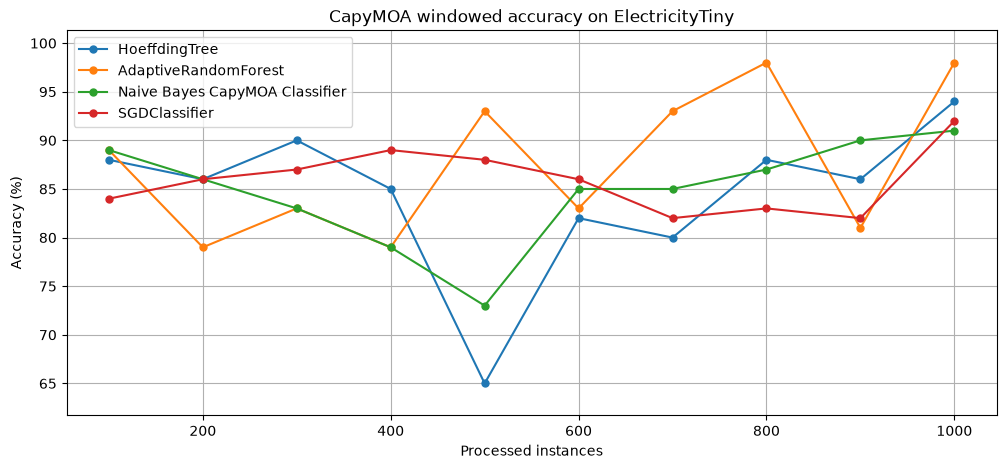

CapyMOA runtime is reported for the 1,000-instance run; ms_per_instance is runtime / 1,000.


In [14]:
plot_windowed_results(
    *capy_evaluations,
    metric='accuracy',
    plot_title='CapyMOA windowed accuracy on ElectricityTiny',
    xlabel='Processed instances',
    ylabel='Accuracy (%)',
    save_only=False,
)

print('CapyMOA runtime is reported for the 1,000-instance run; ms_per_instance is runtime / 1,000.')


On ElectricityTiny, Adaptive Random Forest reaches 87.6% accuracy, followed by Naive Bayes at 84.8%, Logistic SGD at 85.9%, and the Hoeffding tree at 84.4%. The native CapyMOA windowed figure shows the four learners over successive 100-instance windows. The corresponding measured latencies are 2.231, 0.039, 3.209, and 0.340 ms/instance. The comparison table also places these results next to the River Electricity results; because Elec2 and ElectricityTiny are different streams, the comparison is about corresponding learner behaviour and cost, not a strict same-data benchmark.
